# Анализ данных о жилых домах Красноярска

Работа выполнена на вручную собранной базе с использованием OpenStreetMap. Методика и ограничения описаны в одноимённом листе XLSX. Данные охватывают часть города, а расстояния указаны по прямой до объектов, найденных в источнике.

Запускать ячейки нужно по порядку. Ноутбук читает XLSX из папки проекта. Для работы нужны pandas, openpyxl, numpy, matplotlib, plotly и Jupyter.

## 1. Загрузка данных

Размер таблицы, типы полей и три строки в транспонированном виде позволяют проверить, что заголовки, текст и числа прочитались корректно.

In [1]:
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import krasnoyarsk_helpers as charts

path = Path(charts.__file__).with_name('Krasnoyarsk_baza_zhilykh_domov_1.xlsx')
raw = pd.read_excel(path, sheet_name='Данные', keep_default_na=False)

print(f'Загружено строк: {len(raw)}. Столбцов: {raw.shape[1]}.')
print()
raw.info(show_counts=True)
print()
print(raw.head(3).T.to_string(header=False))

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.axisbelow': True,
})

Загружено строк: 9132. Столбцов: 22.

<class 'pandas.DataFrame'>
RangeIndex: 9132 entries, 0 to 9131
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   №                                9132 non-null   int64  
 1   Адрес дома                       9132 non-null   str    
 2   Район                            9132 non-null   str    
 3   Материал стен                    9132 non-null   str    
 4   Этажность                        9132 non-null   object 
 5   Класс жилья                      9132 non-null   str    
 6   Ближайшая остановка, м           9132 non-null   int64  
 7   Парковка                         9132 non-null   str    
 8   Загрязнение воздуха, % (модель)  9132 non-null   float64
 9   Парк, м                          9132 non-null   int64  
 10  Закрытый двор                    9132 non-null   str    
 11  Школа, м                         9132 non-null   int64 

## 2. Описание датасета

Одна строка описывает запись о жилом здании. Числовые признаки — расстояния, этажность и модельный показатель загрязнения. Район, материал стен, класс жилья, парковка, закрытый двор и площадка — категории. Номер, адрес и координаты нужны для идентификации, поиска и карты.

**Отклик** — расстояние до ближайшей остановки в метрах. Он числовой, поэтому в дальнейшем можно поставить задачу регрессии. Здесь изучаем связи и готовим признаки без обучения модели и без масштабирования.

In [2]:
target = 'Ближайшая остановка, м'
air = 'Загрязнение воздуха, % (модель)'
court = 'Закрытый двор'
district = 'Район'
floors, address, coordinates = charts.floors, charts.address, charts.coordinates

distances = [col for col in raw if col.endswith(', м')]
numeric = distances + [floors, air]
service = ['№', address, coordinates]
categorical = [col for col in raw if col not in numeric + service]

data = raw.replace(r'^\s*(?:информация отсутствует)?\s*$', np.nan, regex=True)
data[numeric] = data[numeric].apply(pd.to_numeric, errors='coerce')
# Выгрузка сведений об ограждениях не удалась.
data[court] = np.nan

geo = data[coordinates].str.split(',', n=1, expand=True)
geo = geo.apply(pd.to_numeric, errors='coerce').set_axis(['Широта', 'Долгота'], axis=1)
geo_valid = geo['Широта'].between(-90, 90) & geo['Долгота'].between(-180, 180)
geo = geo.loc[geo_valid]

print('Числовые поля')
print(*numeric, sep='\n')
print()
print('Категориальные поля')
print(*categorical, sep='\n')
print()
print('Служебные поля')
print(*service, sep='\n')

Числовые поля
Ближайшая остановка, м
Парк, м
Школа, м
ТЦ, м
Детский сад, м
Аптека, м
Больница, м
Развлечения, м
Набережная Енисея, м
СТО, м
Травмпункт, м
Этажность
Загрязнение воздуха, % (модель)

Категориальные поля
Район
Материал стен
Класс жилья
Парковка
Закрытый двор
Детская площадка

Служебные поля
№
Адрес дома
Координаты


Все поля прочитаны отдельными столбцами. В исходном файле этажность смешивала числа и текстовую отметку о пропуске. После замены отметок этажность можно показывать на гистограмме и использовать в расчётах. Координаты разделены на широту и долготу для карты. Текстовые категории будут закодированы в разделе 5.

## 3. Качество данных и описательная статистика

В таблице «Разных» — сколько разных значений есть без учёта пропусков. «Встретилось один раз» считает значения, которые встречаются ровно в одной записи. Это помогает отличать идентификатор от признака с повторяющимися значениями.

In [3]:
groups = numeric + categorical + service
quality = pd.DataFrame({
    'Тип после загрузки': raw.dtypes.astype(str),
    'Тип после очистки': data.dtypes.astype(str),
    'Пропусков': data.isna().sum(),
    'Разных': data.nunique(),
    'Встретилось один раз': data.apply(lambda values: values.value_counts().eq(1).sum()),
}).loc[groups]
print(quality.to_string())

missing = data.isna().sum()
print()
print('Пропуски после очистки')
print(missing[missing.gt(0)].to_string())
print()
print(f'Повторяющихся номеров: {data["№"].duplicated().sum()}')
print(f'Адресов с несколькими записями: {data[address].value_counts().gt(1).sum()}')
print(f'Координат вне допустимых границ или с ошибкой формата: {data[coordinates].count() - len(geo)}')
print(f'Отрицательных расстояний: {data[distances].lt(0).sum().sum()}')
print(f'Нулевых расстояний: {data[distances].eq(0).sum().sum()}')

                                Тип после загрузки Тип после очистки  Пропусков  Разных  Встретилось один раз
Ближайшая остановка, м                       int64             int64          0    4413                  2340
Парк, м                                      int64             int64          0    3093                  1701
Школа, м                                     int64             int64          0    3124                  1781
ТЦ, м                                        int64             int64          0    3958                  1785
Детский сад, м                               int64             int64          0    3019                  1598
Аптека, м                                    int64             int64          0    3319                  1753
Больница, м                                  int64             int64          0    3246                  1577
Развлечения, м                               int64             int64          0    3361                  1663
Набережная

Пропуски в этажности оставлены в таблице и исключаются из расчётов по этажности. У материала стен и класса жилья пропуск станет отдельной категорией «Нет сведений». Поле «Закрытый двор» целиком пустое после исправления отметки из источника. Оно не даёт информации для модели.

Номер записи уникален. Адреса повторяются, поэтому удалять записи только по адресу нельзя. Номер и адрес не используются как признаки модели. Координаты полезны для карты, но в этом анализе также оставлены служебными. Класс жилья, часть материалов стен и показатель воздуха получены по правилам из методики. Связи этих полей могут отражать способ расчёта. Нули в расстояниях стоит сверить с исходной геометрией. В материале стен метку «plaster» стоит проверить отдельно. Она описывает штукатурку и может обозначать отделку. Метка неопределённого района обозначает отсутствие точной привязки.

In [4]:
stats = data[numeric].describe().T
stats['Одна из мод'] = data[numeric].mode().iloc[0]
stats = stats.rename(columns={
    'count': 'Заполнено', 'mean': 'Среднее', 'std': 'Ст. откл.',
    'min': 'Мин.', '50%': 'Медиана', 'max': 'Макс.',
})
print(stats.round(2).to_string())
print()
print('Самые частые значения категорий')
categories = data[categorical].astype('string').fillna('Нет сведений')
for col in categorical:
    print(f'\n{col}')
    print(categories[col].value_counts().head(3).to_string())

                                 Заполнено  Среднее  Ст. откл.  Мин.      25%  Медиана      75%    Макс.  Одна из мод
Ближайшая остановка, м              9132.0  2597.04    2798.46   8.0   684.75   1475.0  4212.50  11997.0        167.0
Парк, м                             9132.0  1323.85    1819.07   7.0   234.00    475.0  1502.00   8218.0        119.0
Школа, м                            9132.0  1431.66    1879.09   0.0   340.00    573.0  1622.75   8310.0        394.0
ТЦ, м                               9132.0  2014.69    1645.99   0.0   875.00   1474.0  2494.25   8508.0       1283.0
Детский сад, м                      9132.0  1361.06    1772.43   3.0   309.00    610.0  1301.00   8124.0        363.0
Аптека, м                           9132.0  1481.06    1824.64   1.0   357.00    643.5  1886.00   8392.0        291.0
Больница, м                         9132.0  1438.45    1802.36   0.0   361.75    697.0  1608.50   8886.0        233.0
Развлечения, м                      9132.0  1449.66    1

### Выбросы

Ящик показывает средние 50% значений, линия внутри — медиану. Точки дальше 1,5 межквартильных размахов от края ящика отмечены как выбросы. Правило применяется к числовым полям. Дальнее расстояние или большая этажность могут быть реальными, поэтому отмеченные строки остаются в базе.

Ближайшая остановка, м              359
Парк, м                            1148
Школа, м                           1189
ТЦ, м                               818
Детский сад, м                     1523
Аптека, м                           916
Больница, м                        1014
Развлечения, м                      964
Набережная Енисея, м                281
СТО, м                              751
Травмпункт, м                       735
Этажность                          1022
Загрязнение воздуха, % (модель)       0


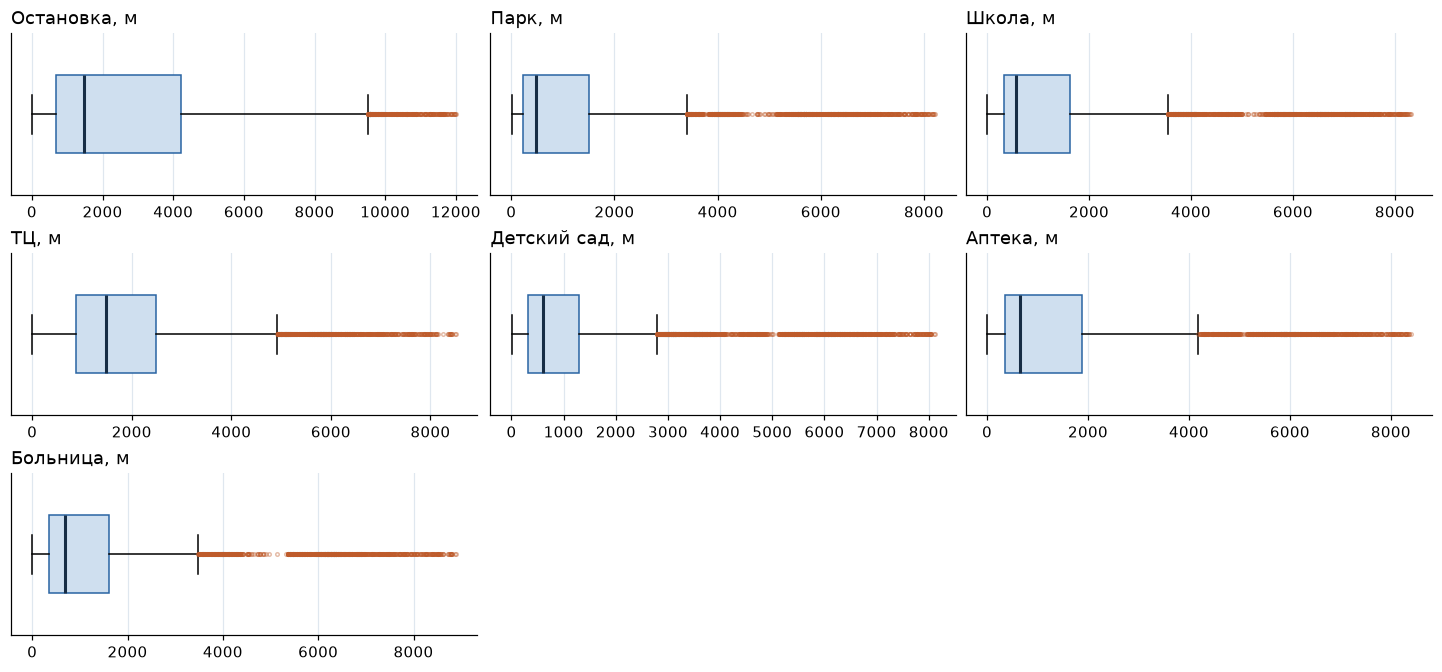

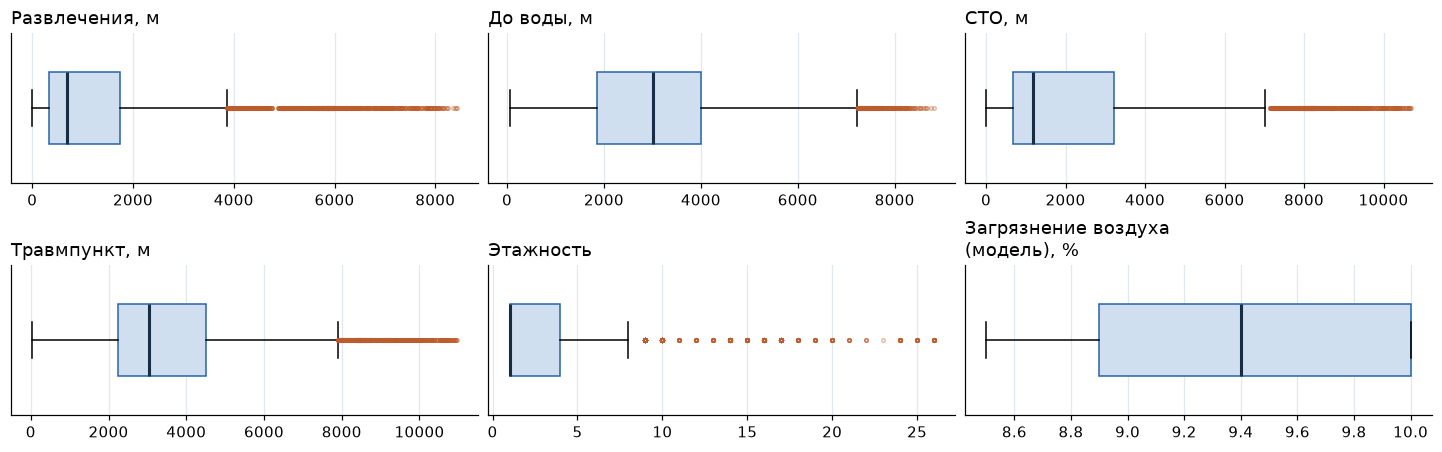

In [5]:
short = {col: col for col in raw}
short.update({
    target: 'Остановка, м',
    'Набережная Енисея, м': 'До воды, м',
    air: 'Загрязнение воздуха (модель), %',
})
q1, q3 = data[numeric].quantile(.25), data[numeric].quantile(.75)
iqr = q3 - q1
outliers = data[numeric].lt(q1 - 1.5 * iqr) | data[numeric].gt(q3 + 1.5 * iqr)
print(outliers.sum().rename('Выбросов').to_string())
charts.panels(numeric[:7], charts.box, short, ncols=3, height=2.0, data=data)
charts.panels(numeric[7:], charts.box, short, ncols=3, height=2.0, data=data)

## 4. Распределения до кодирования

На гистограммах по горизонтали показано значение, по вертикали — число записей. У каждого поля своя шкала. Под графиками есть краткий вывод по каждому числовому полю. Он описывает форму распределения и типичное значение.

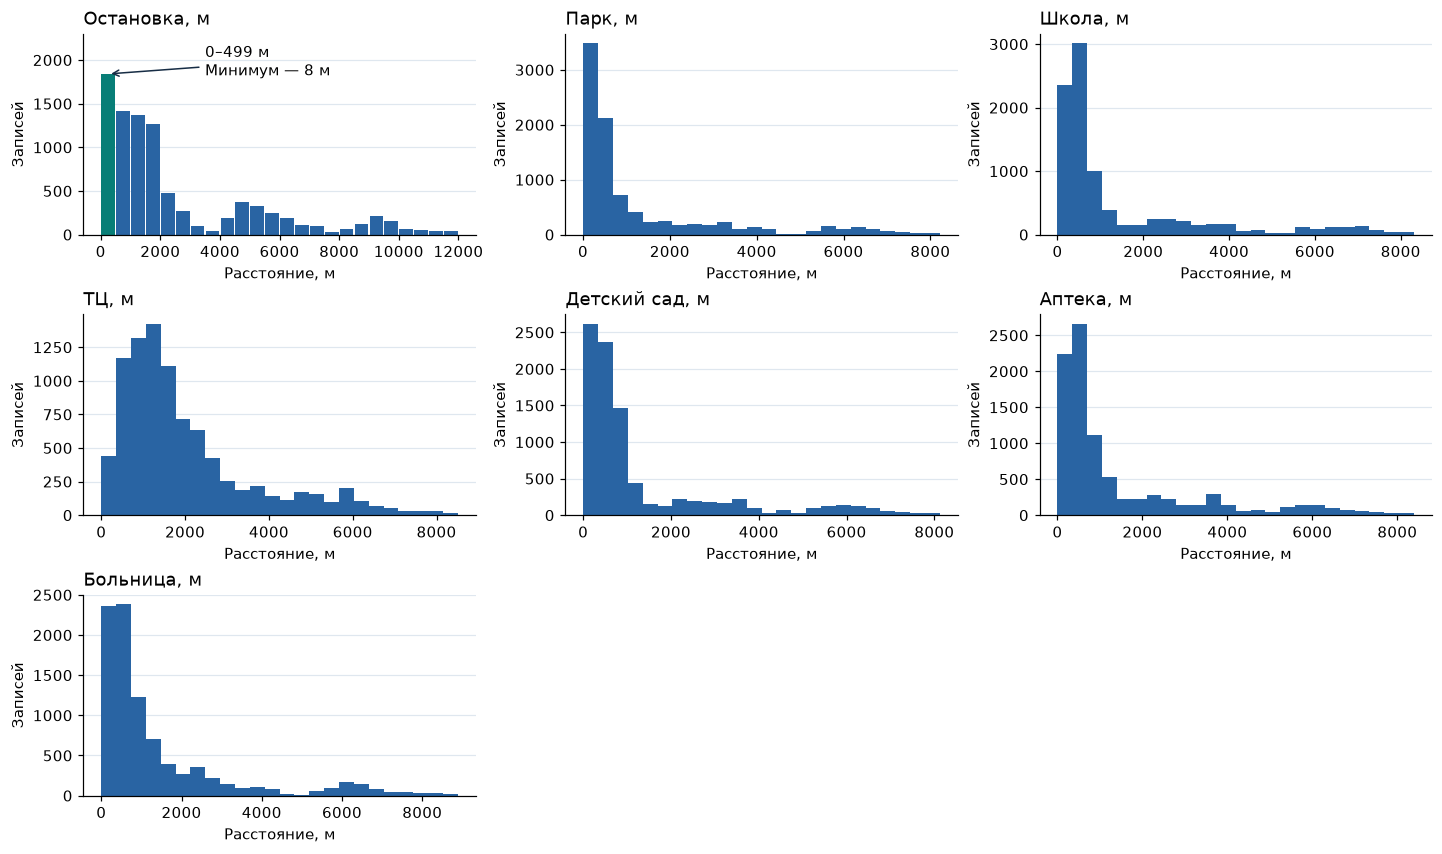

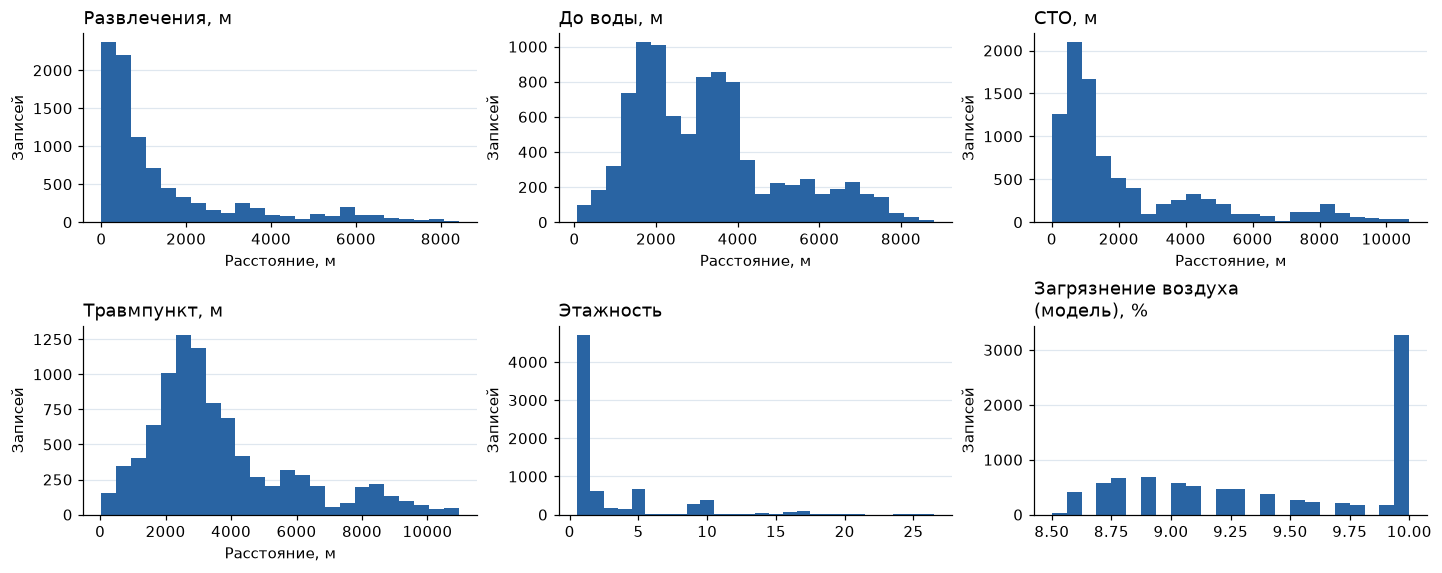

Остановка, м — длиннее правый хвост, медиана 1475.00, частое значение 167.00.
Парк, м — длиннее правый хвост, медиана 475.00, частое значение 119.00.
Школа, м — длиннее правый хвост, медиана 573.00, частое значение 394.00.
ТЦ, м — длиннее правый хвост, медиана 1474.00, частое значение 1283.00.
Детский сад, м — длиннее правый хвост, медиана 610.00, частое значение 363.00.
Аптека, м — длиннее правый хвост, медиана 643.50, частое значение 291.00.
Больница, м — длиннее правый хвост, медиана 697.00, частое значение 233.00.
Развлечения, м — длиннее правый хвост, медиана 700.00, частое значение 342.00.
До воды, м — длиннее правый хвост, медиана 3015.00, частое значение 1665.00.
СТО, м — длиннее правый хвост, медиана 1182.00, частое значение 443.00.
Травмпункт, м — длиннее правый хвост, медиана 3050.00, частое значение 2336.00.
Этажность — длиннее правый хвост, медиана 1.00, частое значение 1.00.
Загрязнение воздуха (модель), % — слабая асимметрия, медиана 9.40, частое значение 10.00.


In [6]:
charts.panels(numeric[:7], charts.histogram, short, ncols=3, height=2.55, data=data)
charts.panels(numeric[7:], charts.histogram, short, ncols=3, height=2.55, data=data)

skew = data[numeric].skew()
for col in numeric:
    if skew[col] >= .5:
        shape = 'длиннее правый хвост'
    elif skew[col] <= -.5:
        shape = 'длиннее левый хвост'
    else:
        shape = 'слабая асимметрия'
    print(f'{short[col]} — {shape}, медиана {stats.loc[col, "Медиана"]:.2f}, '
          f'частое значение {stats.loc[col, "Одна из мод"]:.2f}.')

Для категорий длина столбца показывает частоту. В пояснении под графиками указана самая частая категория каждого поля. Метка «Нет сведений» показывает пропуск в источнике.

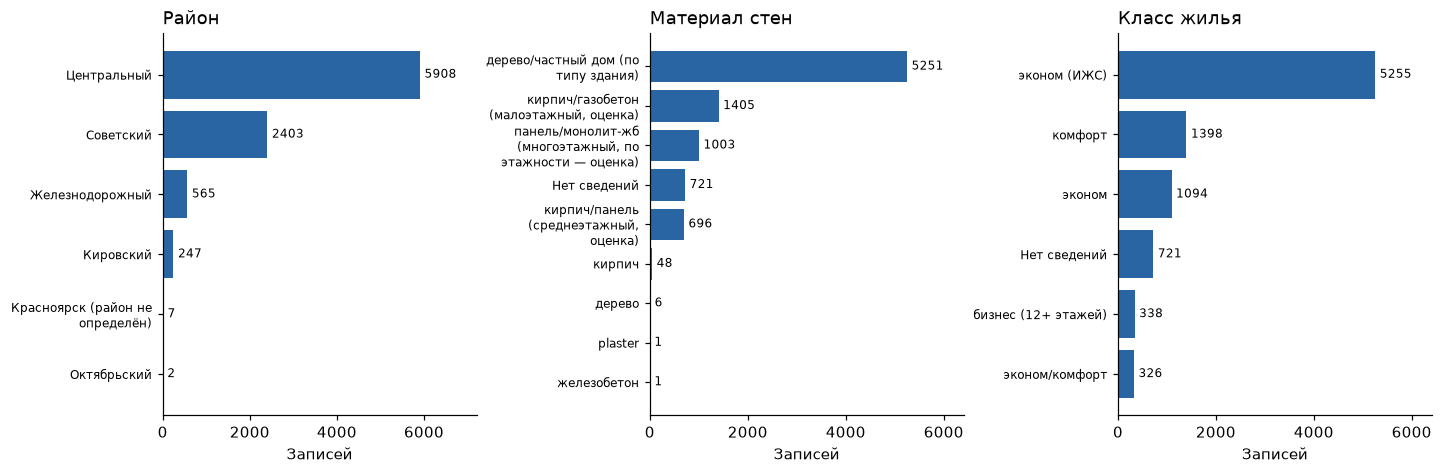

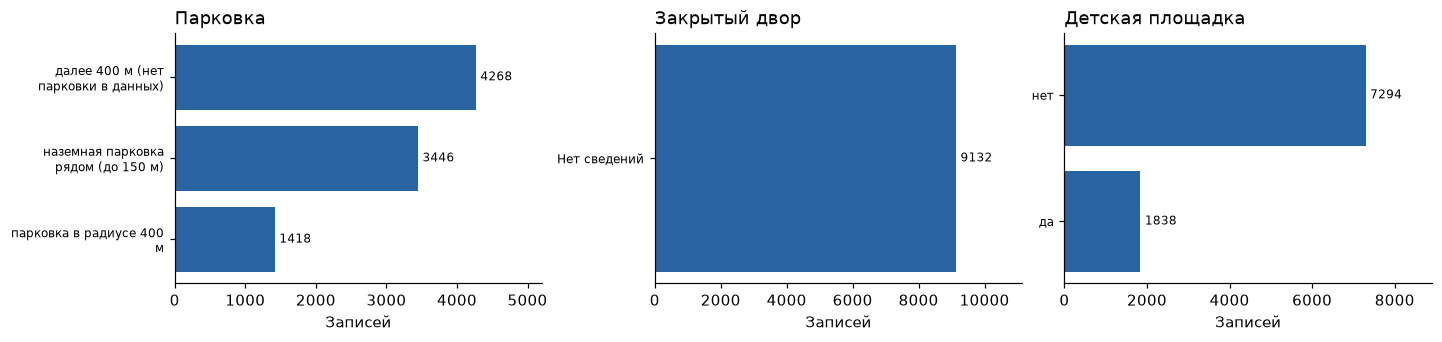

Район — чаще всего «Центральный» (64.7%). Категорий с учётом пропусков: 6.
Материал стен — чаще всего «дерево/частный дом (по типу здания)» (57.5%). Категорий с учётом пропусков: 9.
Класс жилья — чаще всего «эконом (ИЖС)» (57.5%). Категорий с учётом пропусков: 6.
Парковка — чаще всего «далее 400 м (нет парковки в данных)» (46.7%). Категорий с учётом пропусков: 3.
Закрытый двор — чаще всего «Нет сведений» (100.0%). Категорий с учётом пропусков: 1.
Детская площадка — чаще всего «нет» (79.9%). Категорий с учётом пропусков: 2.


In [7]:
def category_bars(ax, col):
    counts = categories[col].value_counts().sort_values()
    labels = [fill(str(label), width=22) for label in counts.index]
    bars = ax.barh(labels, counts, color=charts.blue)
    ax.bar_label(bars, padding=3, fontsize=8)
    ax.margins(x=.22)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_xlabel('Записей')

charts.panels(categorical[:3], category_bars, short, ncols=3, height=4.2)
charts.panels(categorical[3:], category_bars, short, ncols=3, height=3.0)
for col in categorical:
    counts = categories[col].value_counts()
    leader = counts.index[0]
    print(f'{col} — чаще всего «{leader}» ({counts.iloc[0] / len(data):.1%}). '
          f'Категорий с учётом пропусков: {len(counts)}.')

Служебные поля описаны таблицей качества. Номера и адреса нужны для поиска конкретной записи. Пространственное распределение координат показано ниже.

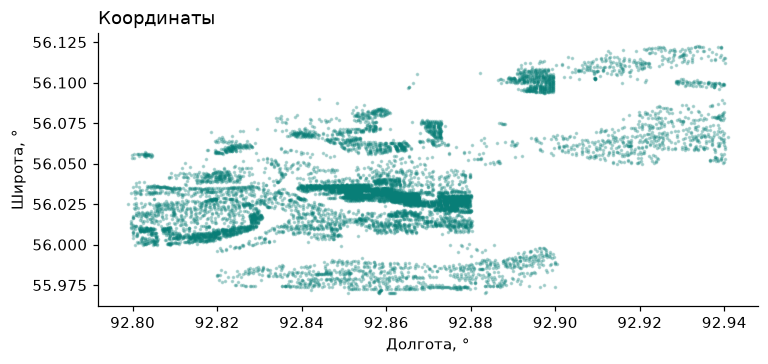

In [8]:
charts.panels([coordinates], charts.category, short, ncols=2, height=3.2,
              geo=geo, raw=raw, data=data)

## 5. Кодирование и распределения после кодирования

Применяем one-hot. У каждой категории свой столбец из нулей и единиц. Единица означает, что у дома есть эта категория. Так кодирование не задаёт порядок районам или материалам стен. Полностью пустой «Закрытый двор» исключён, число строк сохранено.

In [9]:
encoded_categories = categories.drop(columns=court).astype('category')
dummies = pd.get_dummies(encoded_categories, prefix_sep=' = ', dtype='int8')
encoded = data[numeric].join(dummies)
X = encoded.drop(columns=target)
y = encoded[target]

print(f'Строк после кодирования: {len(encoded)}')
print(f'Признаков для будущей модели: {X.shape[1]}, в том числе индикаторов: {dummies.shape[1]}')
print()
print(encoded.iloc[:3].T.to_string(header=False))

indicator_stats = pd.DataFrame({
    'Тип': dummies.dtypes.astype(str),
    'Пропусков': dummies.isna().sum(),
    'Нулей': dummies.eq(0).sum(),
    'Единиц': dummies.eq(1).sum(),
    'Разных': dummies.nunique(),
    'Встретилось один раз': dummies.eq(0).sum().eq(1).astype(int) + dummies.eq(1).sum().eq(1).astype(int),
    'Мода': dummies.mode().iloc[0],
    'Доля единиц, %': dummies.mean().mul(100).round(2),
})
print()
print(indicator_stats.to_string())
print()
print('Пропусков в числовых полях:', encoded[numeric].isna().sum().sum())
print('Индикаторов с одним значением:', indicator_stats['Разных'].eq(1).sum())
print('Числовые поля совпадают с исходными очищенными:', encoded[numeric].equals(data[numeric]))

Строк после кодирования: 9132
Признаков для будущей модели: 38, в том числе индикаторов: 26

Ближайшая остановка, м                                                   5121.0  5052.0  5567.0
Парк, м                                                                   348.0   259.0  1638.0
Школа, м                                                                  370.0   346.0  2065.0
ТЦ, м                                                                     722.0   670.0  2211.0
Детский сад, м                                                            243.0   226.0  1580.0
Аптека, м                                                                1280.0  1252.0  1837.0
Больница, м                                                               975.0   896.0  2290.0
Развлечения, м                                                            512.0   423.0  1675.0
Набережная Енисея, м                                                     1135.0  1109.0  1776.0
СТО, м                                     

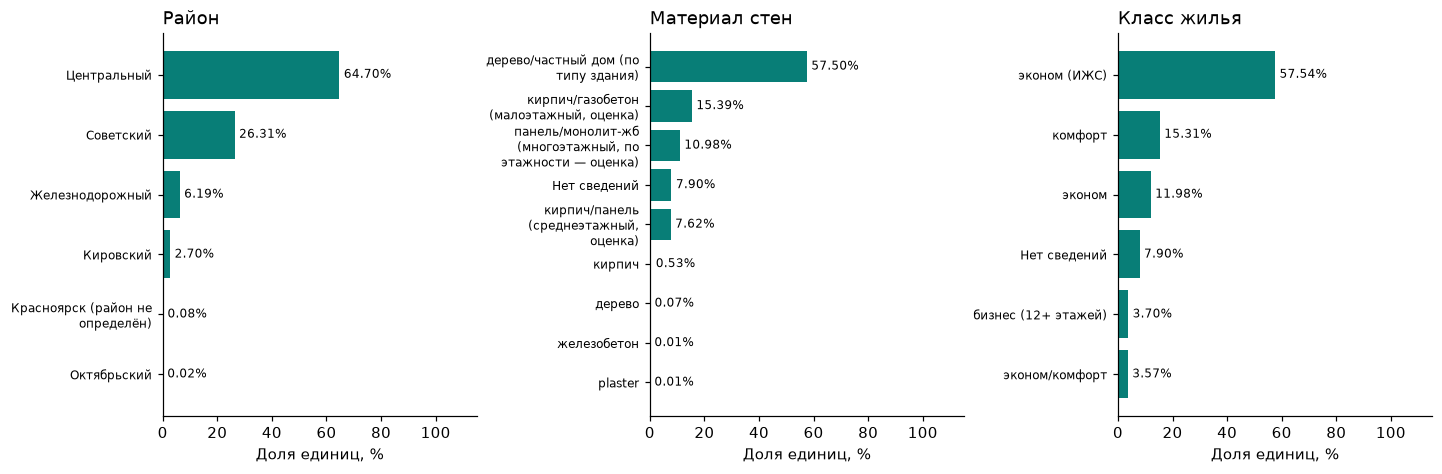

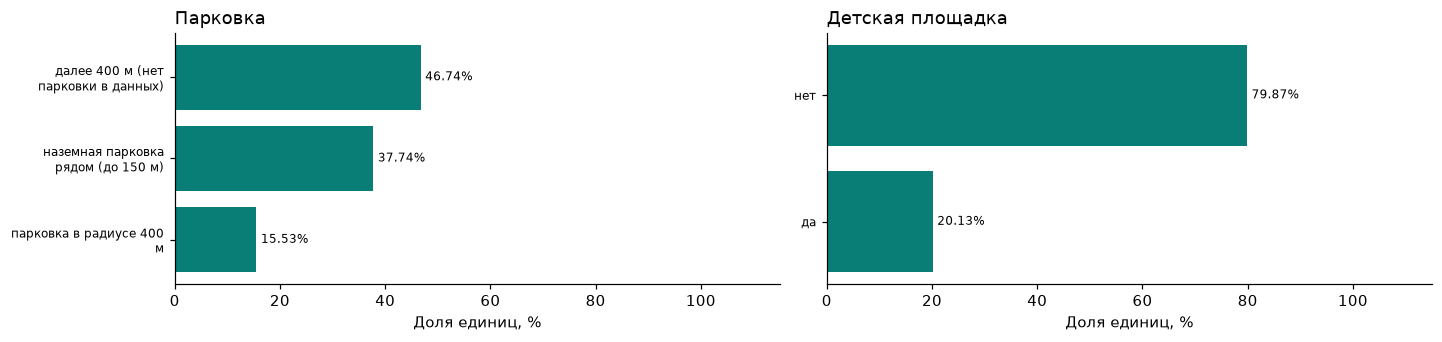

Район — кодирование дало 6 индикаторов. Больше всего единиц у «Центральный» (64.7%).
Материал стен — кодирование дало 9 индикаторов. Больше всего единиц у «дерево/частный дом (по типу здания)» (57.5%).
Класс жилья — кодирование дало 6 индикаторов. Больше всего единиц у «эконом (ИЖС)» (57.5%).
Парковка — кодирование дало 3 индикаторов. Больше всего единиц у «далее 400 м (нет парковки в данных)» (46.7%).
Детская площадка — кодирование дало 2 индикаторов. Больше всего единиц у «нет» (79.9%).


In [10]:
def encoded_bars(ax, col):
    prefix = f'{col} = '
    rates = indicator_stats.loc[indicator_stats.index.str.startswith(prefix), 'Доля единиц, %']
    rates = rates.sort_values().rename(index=lambda label: label.removeprefix(prefix))
    labels = [fill(label, width=22) for label in rates.index]
    bars = ax.barh(labels, rates, color=charts.teal)
    ax.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=8)
    ax.set(xlim=(0, 115), xlabel='Доля единиц, %')
    ax.set_xticks(range(0, 101, 20))
    ax.tick_params(axis='y', labelsize=8)

fields = list(encoded_categories)
charts.panels(fields[:3], encoded_bars, short, ncols=3, height=4.2)
charts.panels(fields[3:], encoded_bars, short, ncols=2, height=3.0)

for col in fields:
    rates = indicator_stats.loc[indicator_stats.index.str.startswith(f'{col} = '), 'Доля единиц, %']
    leader = rates.idxmax().split(' = ', 1)[1]
    print(f'{col} — кодирование дало {len(rates)} индикаторов. '
          f'Больше всего единиц у «{leader}» ({rates.max():.1f}%).')

Доля единиц соответствует частоте исходной категории. Остальное — нули, поэтому графики и таблица описывают распределение каждого индикатора. Показаны также мода, число разных значений и константные столбцы. Значения 0 и 1 допустимы по определению, и искать выбросы правилом ящика с усами для них нет смысла. Числовые поля сохранили исходные единицы, распределения и выбросы из разделов 3–4. Перед обучением способ заполнения этажности нужно подобрать на обучающей части данных. У всех индикаторов одной исходной категории сумма по строке равна единице. В линейной модели со свободным членом одну категорию можно оставить базовой, чтобы избавиться от точной зависимости между столбцами.

## 6. Связи между признаками

Матрица показывает коэффициенты Спирмена для числовых признаков без отклика. Значения близко к +1 означают, что признаки обычно растут вместе, а близко к −1 — что один растёт, когда другой уменьшается.

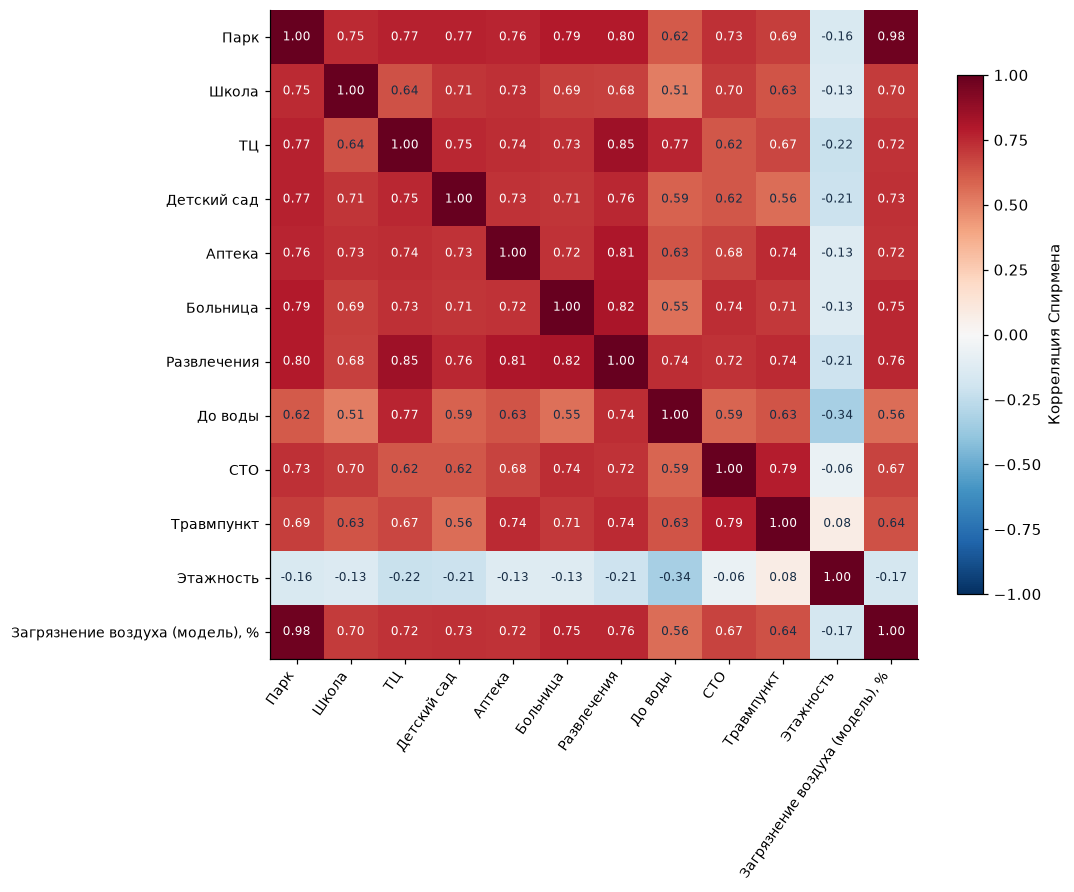

In [11]:
predictors = [col for col in numeric if col != target]
rho = data[predictors].corr(method='spearman')
axis_labels = [short[col].removesuffix(', м') for col in predictors]

fig, ax = plt.subplots(figsize=(10, 8), layout='constrained')
matrix = ax.imshow(rho, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(axis_labels)), axis_labels, rotation=55, ha='right', fontsize=9)
ax.set_yticks(range(len(axis_labels)), axis_labels, fontsize=9)
for row, values in enumerate(rho.to_numpy()):
    for col, value in enumerate(values):
        ax.text(col, row, f'{value:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(value) > .65 else charts.ink)
fig.colorbar(matrix, ax=ax, label='Корреляция Спирмена', shrink=.8)
plt.show()

ТЦ, м и Развлечения, м — 0.85.
Больница, м и Развлечения, м — 0.82.


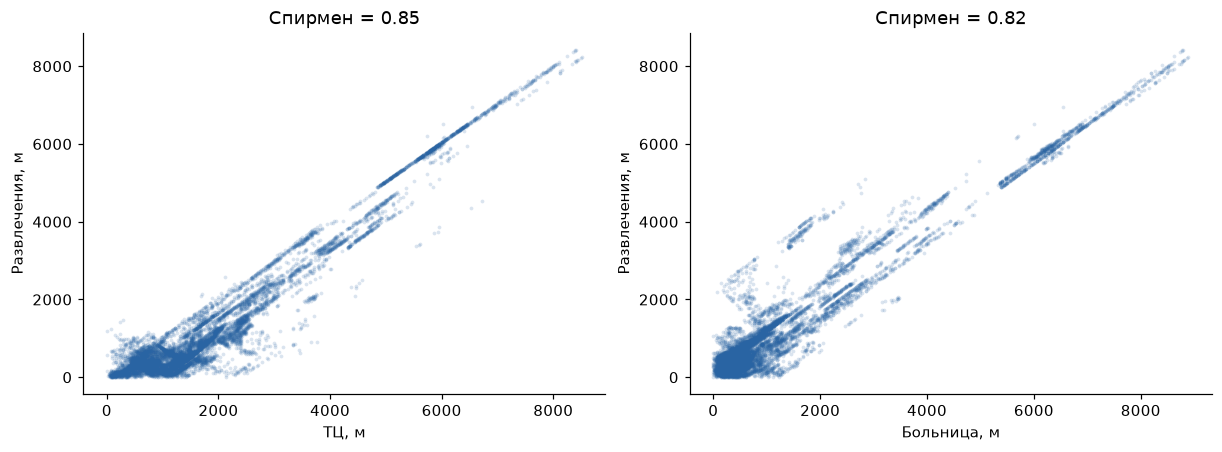

Парк и модель воздуха — 0.98.


In [12]:
# Выбираем две самые сильные связи между измеренными расстояниями.
other_distances = [col for col in distances if col != target]
distance_rho = rho.loc[other_distances, other_distances]
upper = np.triu(np.ones(distance_rho.shape, dtype=bool), k=1)
pairs = distance_rho.where(upper).stack().dropna()
strongest = pairs.abs().nlargest(2).index

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, (left, right) in zip(axes, strongest):
    coeff = pairs.loc[(left, right)]
    ax.scatter(data[left], data[right], s=6, alpha=.17, color=charts.blue, linewidths=0)
    ax.set(xlabel=short[left], ylabel=short[right], title=f'Спирмен = {coeff:.2f}')
    print(f'{short[left]} и {short[right]} — {coeff:.2f}.')
plt.show()

print(f'Парк и модель воздуха — {rho.loc["Парк, м", air]:.2f}.')

Удалённость от разных объектов часто растёт вместе. Это может отражать расположение зданий и полноту разметки. Связь парка с моделью воздуха нужно читать отдельно, потому что расстояние до парка уже учитывается в формуле модели.

## 7. Связи признаков с откликом

Сначала сравниваем расстояние до остановки с двумя числовыми признаками, у которых самая сильная связь по Спирмену. Затем сравниваем отклик по районам и этажности. Для районных графиков берём группы как минимум с 30 записями.

Развлечения, м                     0.84
СТО, м                             0.83
ТЦ, м                              0.81
Травмпункт, м                      0.80
Набережная Енисея, м               0.78
Больница, м                        0.77
Аптека, м                          0.76
Парк, м                            0.76
Загрязнение воздуха, % (модель)    0.72
Детский сад, м                     0.71
Школа, м                           0.69
Этажность                         -0.14


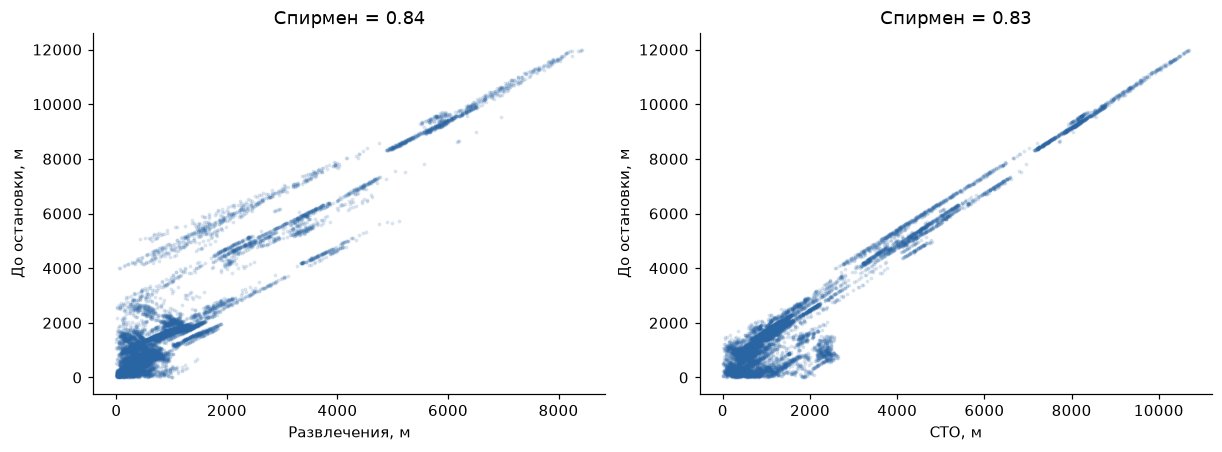

In [13]:
response_rho = encoded[predictors + [target]].corr(method='spearman')[target].drop(target)
ranking = response_rho.abs().sort_values(ascending=False).index
print(response_rho.loc[ranking].round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, col in zip(axes, ranking[:2]):
    ax.scatter(data[col], y, s=6, alpha=.17, color=charts.blue, linewidths=0)
    ax.set(xlabel=short[col], ylabel='До остановки, м', title=f'Спирмен = {response_rho[col]:.2f}')
plt.show()

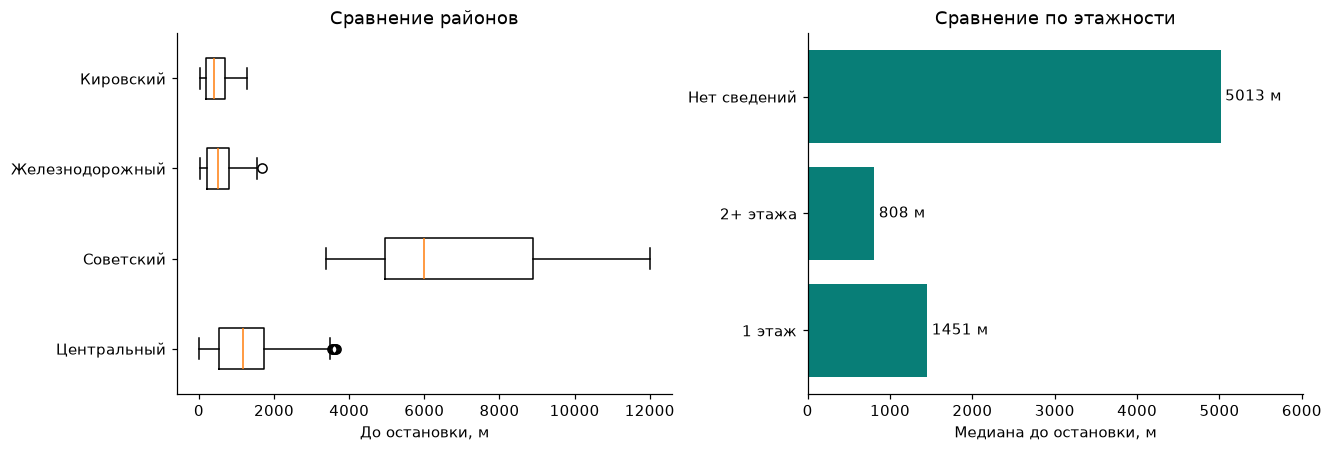

Медианы по районам, м
Район
Железнодорожный     500.0
Кировский           408.0
Советский          5984.0
Центральный        1169.0

Медианы по этажности, м
1 этаж          1451.0
2+ этажа         808.0
Нет сведений    5013.0


In [14]:
district_counts = data[district].value_counts()
districts = district_counts[district_counts.ge(30)].index
district_groups = [data.loc[data[district].eq(name), target] for name in districts]

floor_masks = {
    '1 этаж': data[floors].eq(1),
    '2+ этажа': data[floors].ge(2),
    'Нет сведений': data[floors].isna(),
}
floor_medians = pd.Series({
    name: data.loc[mask, target].median() for name, mask in floor_masks.items()
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
axes[0].boxplot(district_groups, tick_labels=districts, orientation='horizontal')
axes[0].set(title='Сравнение районов', xlabel='До остановки, м')
bars = axes[1].barh(floor_medians.index, floor_medians, color=charts.teal)
axes[1].bar_label(bars, fmt='%.0f м', padding=3)
axes[1].margins(x=.20)
axes[1].set(title='Сравнение по этажности', xlabel='Медиана до остановки, м')
plt.show()

print('Медианы по районам, м')
print(data.loc[data[district].isin(districts)].groupby(district)[target].median().round(1).to_string())
print()
print('Медианы по этажности, м')
print(floor_medians.round(1).to_string())

### Итоги отчёта

- Сильнее всего расстояние до остановки связано с удалённостью от других объектов. Это наблюдение по имеющимся записям.
- В общей выборке медиана для домов с 2+ этажами меньше, чем для одноэтажных. Такое сравнение зависит от состава районов и от того, у каких домов указана этажность.
- У Советского района медиана до остановки заметно выше. Для интерпретации результата важно проверить, одинаково ли хорошо нанесены остановки в разных районах.
- Строки с выбросами сохранены. Категории переведены в индикаторы. Масштабирование и обучение модели в этой работе не выполнялись.